In [7]:
# 第一部分：导入必要的库
# ============================================

import mindspore as ms
from mindspore import nn
import mindspore.dataset as ds
import mindspore.ops as P
from mindspore.nn import SoftmaxCrossEntropyWithLogits
from mindspore.common.initializer import Normal

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, RY, RZ, CNOT, Rxx, Ryy, Rzz
from mindquantum.core.parameterresolver import PRGenerator
from mindquantum.core.operators import QubitOperator, Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.framework import MQLayer
from mindspore import Tensor
import warnings
warnings.filterwarnings('ignore')
# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei']  # 使用黑体显示中文
plt.rcParams['axes.unicode_minus'] = False    # 解决负号显示异常

In [8]:
# 第二部分：可调参数配置区
# ============================================

# 数据相关参数
SAMPLE_RATIO = 1            # 数据采样比例
TEST_SIZE = 0.2                # 测试集比例
PCA_COMPONENTS = 8             # PCA降维维度（与量子比特数一致）
BATCH_SIZE = 32                 # 批处理大小

# 量子电路参数
NUM_QUBITS = 8                  # 量子比特数
LAYERS_LIST = [1, 2, 3]         # 待测试的Ansatz层数（1~3层）
ANSAYZ_TYPE = 'sequential_su4'  # 默认Ansatz类型，将在主循环中覆盖

# 训练参数
NUM_EPOCHS = 150                 # 训练轮数
LEARNING_RATE = 0.01             # 学习率
PARALLEL_WORKER = 2              # 并行工作器数量

# MindSpore配置
MS_MODE = ms.PYNATIVE_MODE        # 运行模式
MS_DEVICE = "CPU"                 # 设备目标
SEED = 42                         # 随机种子

# 初始化设置
# ============================================
ms.set_context(mode=MS_MODE, device_target=MS_DEVICE)
ms.set_seed(SEED)
np.random.seed(SEED)

[WARNING] ME(25924:9320,MainProcess):2026-03-10-18:58:50.982.000 [mindspore\context.py:1334] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [9]:
# 第三部分：数据加载和处理函数
# ============================================

def load_mnist_data():
    """加载MNIST数据集（与原始代码相同）"""
    import os
    from torchvision.datasets import MNIST
    
    print("正在下载/加载MNIST数据集...")
    data_dir = "./MNIST"
    os.makedirs(data_dir, exist_ok=True)
    
    try:
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    except:
        # 如果下载失败，尝试使用临时目录
        import tempfile
        temp_dir = tempfile.gettempdir()
        data_dir = os.path.join(temp_dir, "MNIST")
        print(f"使用临时目录: {data_dir}")
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    
    def extract_data(dataset):
        images = dataset.data.numpy().astype(np.float32) / 255.0
        labels = dataset.targets.numpy()
        images_flatten = images.reshape(len(images), -1)
        return images_flatten, labels
    
    train_images, train_labels = extract_data(train_set)
    test_images, test_labels = extract_data(test_set)
    
    # 合并数据
    all_images = np.concatenate([train_images, test_images])
    all_labels = np.concatenate([train_labels, test_labels])
    
    # 数据采样
    sampled_indices = np.random.choice(
        len(all_images), 
        int(len(all_images) * SAMPLE_RATIO), 
        replace=False
    )
    
    sampled_images = all_images[sampled_indices]
    sampled_labels = all_labels[sampled_indices]
    
    print(f"总样本数: {len(all_images)}, 采样后: {len(sampled_images)}")
    print(f"类别分布: {np.unique(sampled_labels, return_counts=True)}")
    
    return sampled_images, sampled_labels


def preprocess_data(images, labels, scaler=None, pca=None, is_train=True):
    """数据预处理：PCA降维 + MinMax归一化到[-1,1]，返回MindSpore数据集"""
    if is_train:
        pca = PCA(n_components=PCA_COMPONENTS)
        pca_data = pca.fit_transform(images)
        print(f"PCA解释方差比: {np.sum(pca.explained_variance_ratio_):.4f}")
        
        # 基础归一化到[-1, 1]范围
        scaler = MinMaxScaler(feature_range=(-1, 1))
        scaled_data = scaler.fit_transform(pca_data)
    else:
        pca_data = pca.transform(images)
        scaled_data = scaler.transform(pca_data)
    
    # 创建MindSpore数据集
    dataset = ds.NumpySlicesDataset(
        data=(scaled_data, labels.astype(np.int32)),
        column_names=["features", "labels"],
        shuffle=is_train
    ).batch(BATCH_SIZE)
    
    return dataset, scaler, pca

In [10]:
# 第四部分：量子电路构建函数
# ============================================

def build_encoder():
    """构建编码器电路（固定不变）"""
    prg = PRGenerator('alpha')
    encoder = Circuit()
    encoder += UN(H, NUM_QUBITS)
    
    for i in range(NUM_QUBITS):
        encoder += RY(prg.new()).on(i)
    
    # 局部 Brickwall 纠缠（一层即可）
    for i in range(0, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    for i in range(1, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    
    encoder = encoder.no_grad()
    encoder.as_encoder()
    return encoder

def build_sequential_su4_ansatz(num_layers):
    """构建顺序SU4 Ansatz"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    for layer in range(num_layers):
        # 单比特旋转层
        for qubit in range(NUM_QUBITS):
            ansatz += RY(theta_prg.new()).on(qubit)
            ansatz += RZ(theta_prg.new()).on(qubit)
        
        # 顺序两比特门层
        for i in range(NUM_QUBITS - 1):
            ansatz += Rxx(theta_prg.new()).on([i, i + 1])
            ansatz += Ryy(theta_prg.new()).on([i, i + 1])
            ansatz += Rzz(theta_prg.new()).on([i, i + 1])
            
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i + 1)
            ansatz += RZ(theta_prg.new()).on(i + 1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RZ(theta_prg.new()).on(qubit)
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz

def build_center_sequential_su4_ansatz(num_layers):
    """构建中心顺序SU4 Ansatz"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    # 初始单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RY(theta_prg.new()).on(qubit)
        ansatz += RZ(theta_prg.new()).on(qubit)
    
    for layer in range(num_layers):
        center = NUM_QUBITS // 2
        
        # 左半部分
        for i in range(center - 1, 0, -1):
            ansatz += Rxx(theta_prg.new()).on([i-1, i])
            ansatz += Ryy(theta_prg.new()).on([i-1, i])
            ansatz += Rzz(theta_prg.new()).on([i-1, i])
            
            ansatz += RY(theta_prg.new()).on(i-1)
            ansatz += RZ(theta_prg.new()).on(i-1)
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
        
        # 右半部分
        for i in range(center, NUM_QUBITS - 1):
            ansatz += Rxx(theta_prg.new()).on([i, i+1])
            ansatz += Ryy(theta_prg.new()).on([i, i+1])
            ansatz += Rzz(theta_prg.new()).on([i, i+1])
            
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i+1)
            ansatz += RZ(theta_prg.new()).on(i+1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RZ(theta_prg.new()).on(qubit)
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz

def build_so4_ansatz(num_layers):
    """构建SO(4)门电路"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    # 初始单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RY(theta_prg.new()).on(qubit)
    
    for layer in range(num_layers):
        for i in range(NUM_QUBITS - 1):
            ansatz += Ryy(theta_prg.new()).on([i, i+1])
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i+1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz

def build_ansatz(ansatz_type, num_layers):
    """根据类型和层数构建Ansatz电路"""
    if ansatz_type == 'sequential_su4':
        return build_sequential_su4_ansatz(num_layers)
    elif ansatz_type == 'center_sequential_su4':
        return build_center_sequential_su4_ansatz(num_layers)
    elif ansatz_type == 'so4':
        return build_so4_ansatz(num_layers)
    else:
        raise ValueError(f"未知的Ansatz类型: {ansatz_type}")

def create_hamiltonians():
    """创建测量哈密顿量 - 仅测量单比特Z（用于10分类）"""
    hams = []
    for i in range(NUM_QUBITS):
        hams.append(Hamiltonian(QubitOperator(f'Z{i}', 1.0)))
    return hams

In [11]:
# 第五部分：神经网络定义与训练
# ============================================

class HybridQuantumNet(nn.Cell):
    """混合量子-经典神经网络（仅Z测量，无缩放层）"""
    def __init__(self, quantum_net, num_classes=10):
        super(HybridQuantumNet, self).__init__()
        self.quantum_net = quantum_net
        # 测量维度 = 量子比特数（每个比特一个Z期望值）
        self.fc = nn.Dense(NUM_QUBITS, num_classes, weight_init=Normal(0.02))
        
    def construct(self, x):
        # 确保输入为二维 [batch_size, features]
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        elif len(x.shape) > 2:
            x = x.reshape(x.shape[0], -1)
        
        # 量子层输出Z测量值，形状 [batch_size, NUM_QUBITS]
        quantum_out = self.quantum_net(x)
        # 直接送入全连接层分类
        logits = self.fc(quantum_out)
        return logits

def train_model(train_dataset, val_dataset, ansatz_type, num_layers, 
                num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE):
    """训练模型（支持指定Ansatz类型和层数）"""
    print(f"\n开始训练: Ansatz类型={ansatz_type}, 层数={num_layers}")
    
    # 构建量子电路
    print("构建量子电路...")
    encoder = build_encoder()
    ansatz = build_ansatz(ansatz_type, num_layers)
    full_circuit = encoder + ansatz
    
    print("量子电路构建完成:")
    print(f"  编码器: {encoder.n_qubits}量子比特")
    print(f"  Ansatz: {ansatz.n_qubits}量子比特，{num_layers}层")
    
    # 创建哈密顿量和梯度算子（仅Z测量）
    print("创建哈密顿量和梯度算子...")
    hams = create_hamiltonians()
    print(f"  哈密顿量数量: {len(hams)} (单比特Z)")
    
    sim = Simulator('mqvector', NUM_QUBITS)
    grad_ops = sim.get_expectation_with_grad(
        hams, full_circuit, parallel_worker=PARALLEL_WORKER
    )
    
    # 创建量子层和混合网络
    print("创建神经网络...")
    quantum_net = MQLayer(grad_ops)
    net = HybridQuantumNet(quantum_net, num_classes=10)
    
    # 损失函数和优化器
    loss_fn = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
    optimizer = nn.Adam(net.trainable_params(), learning_rate=learning_rate)
    
    # 定义前向传播和梯度函数
    def forward_fn(data, label):
        if len(data.shape) == 1:
            data = data.reshape(1, -1)
        logits = net(data)
        loss = loss_fn(logits, label)
        return loss, logits
    
    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)
    
    # 训练循环
    train_losses = []
    val_accuracies = []
    best_val_acc = 0.0
    
    print(f"\n开始训练循环 ({num_epochs} epochs)...")
    
    for epoch in range(num_epochs):
        # 训练
        net.set_train()
        epoch_loss = 0
        step = 0
        
        for data, label in train_dataset.create_tuple_iterator():
            (loss, _), grads = grad_fn(data, label)
            optimizer(grads)
            epoch_loss += loss.asnumpy()
            step += 1
        
        avg_loss = epoch_loss / step if step > 0 else 0
        train_losses.append(avg_loss)
        
        # 验证
        net.set_train(False)
        correct = 0
        total = 0
        
        for data, label in val_dataset.create_tuple_iterator():
            if len(data.shape) == 1:
                data = data.reshape(1, -1)
            logits = net(data)
            predict = ms.ops.Argmax(output_type=ms.int32)(logits)
            correct += (predict == label).asnumpy().sum()
            total += len(label)
        
        val_acc = correct / total if total > 0 else 0
        val_accuracies.append(val_acc)
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
        
        # 打印进度
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: "
                  f"训练损失={avg_loss:.4f}, 验证准确率={val_acc:.4f}")
    
    print(f"\n训练完成! 最佳验证准确率: {best_val_acc:.4f}")
    
    return train_losses, val_accuracies, best_val_acc

步骤1：加载MNIST数据
正在下载/加载MNIST数据集...
总样本数: 70000, 采样后: 70000
类别分布: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int64), array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958],
      dtype=int64))
数据大小: 70000

步骤2：划分数据集
训练集: 56000 样本, 测试集: 14000 样本

步骤3：PCA降维与归一化
PCA解释方差比: 0.4384

步骤4：开始9组实验

实验 sequential_su4_L1 开始

开始训练: Ansatz类型=sequential_su4, 层数=1
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，1层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=1.0417, 验证准确率=0.7641
Epoch  10/150: 训练损失=0.6067, 验证准确率=0.8047
Epoch  20/150: 训练损失=0.5759, 验证准确率=0.8158
Epoch  30/150: 训练损失=0.5696, 验证准确率=0.8178
Epoch  40/150: 训练损失=0.5657, 验证准确率=0.8203
Epoch  50/150: 训练损失=0.5608, 验证准确率=0.8241
Epoch  60/150: 训练损失=0.5543, 验证准确率=0.8271
Epoch  70/150: 训练损失=0.5509, 验证准确率=0.8279
Epoch  80/150: 训练损失=0.5490, 验证准确率=0.8286
Epoch  90/150: 训练损失=0.5475, 验证准确率=0.8291
Epoch 100/150: 训练损失=0.5463, 验证准确率=0.8297
Epoch 110/150: 训练损失=0.5454, 验证准确率=0.8294
Epoch 120/150: 训练损失=0.5446

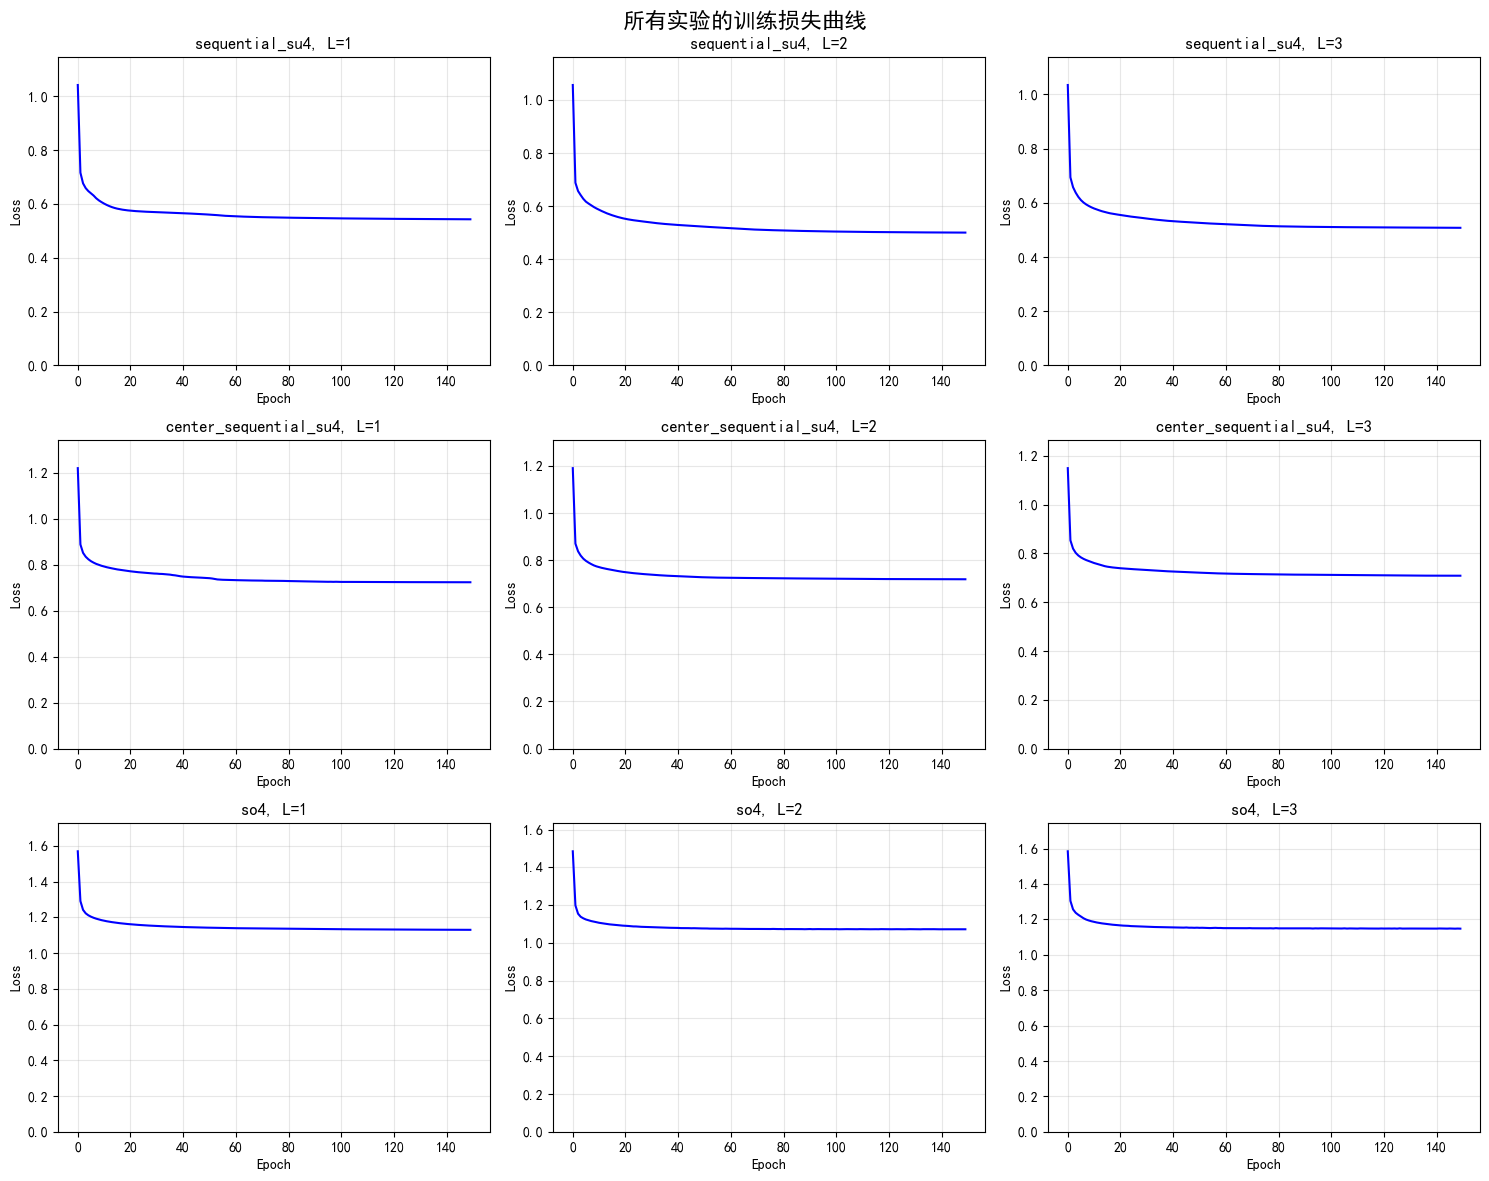

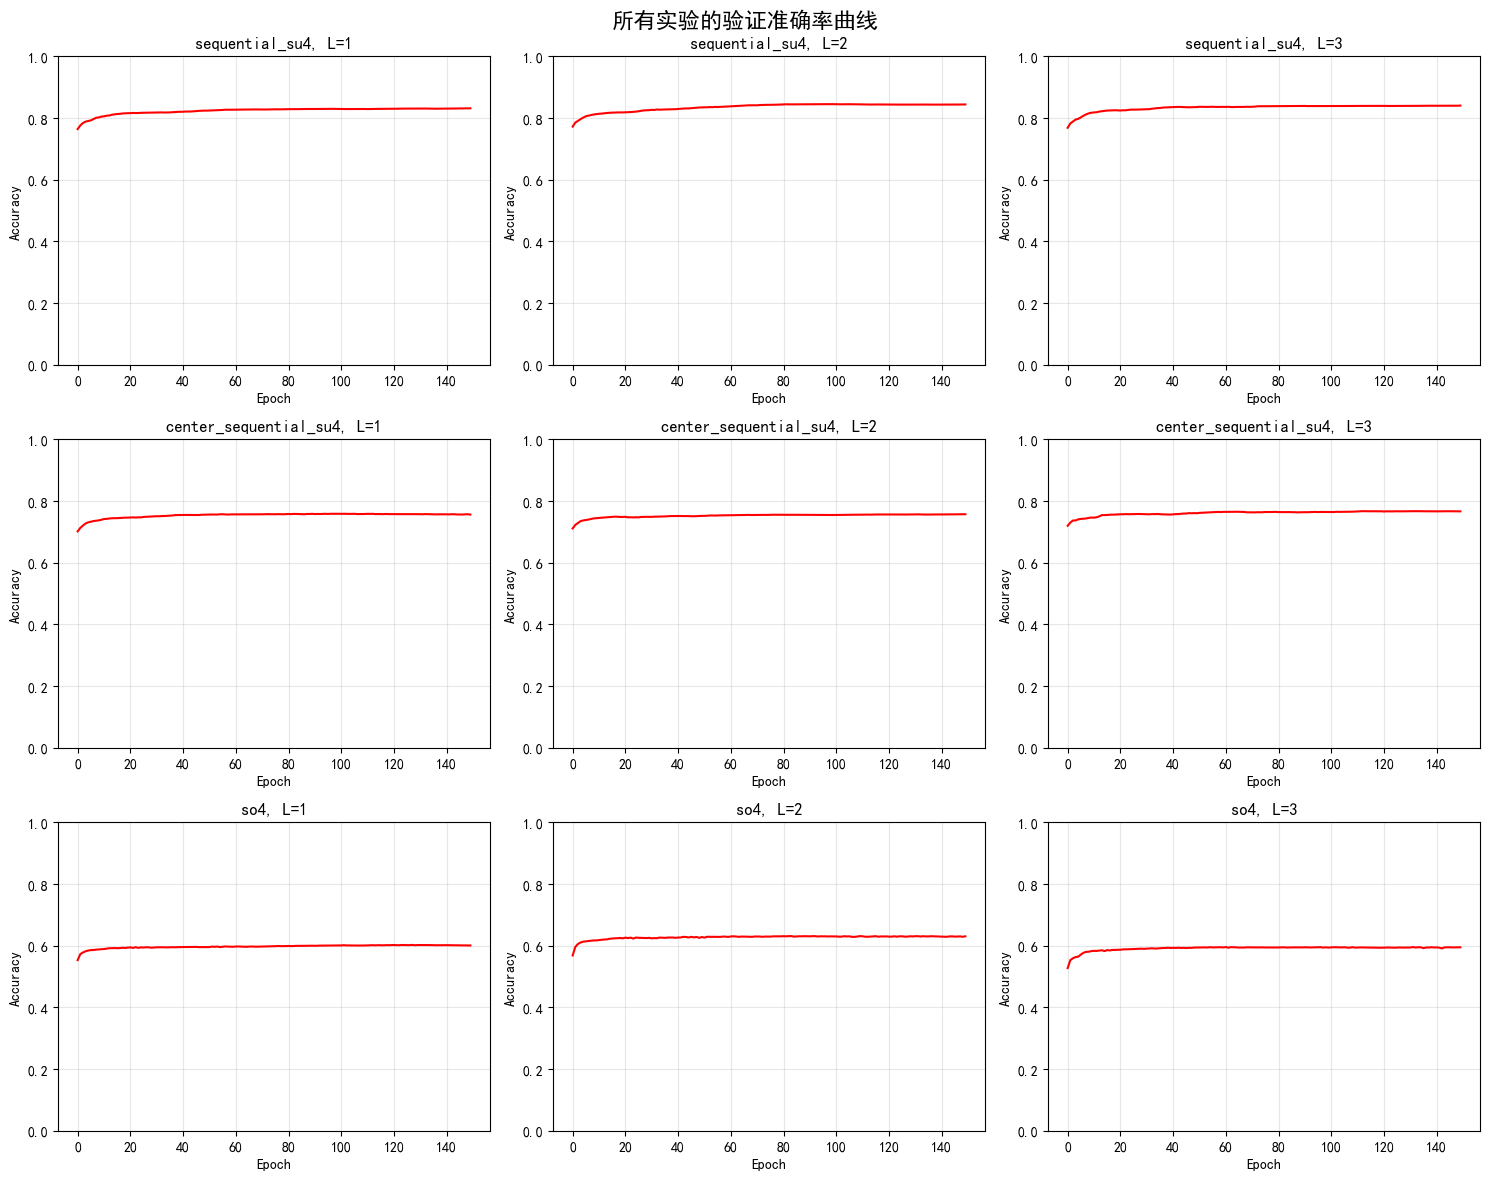

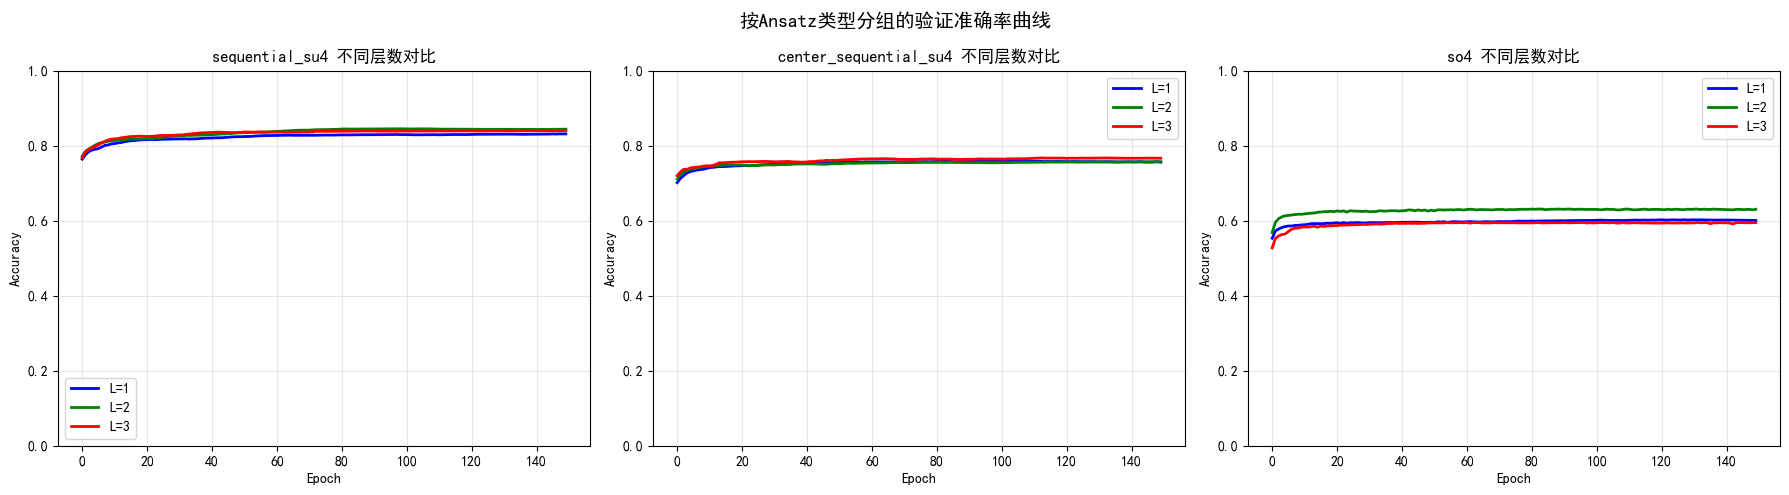

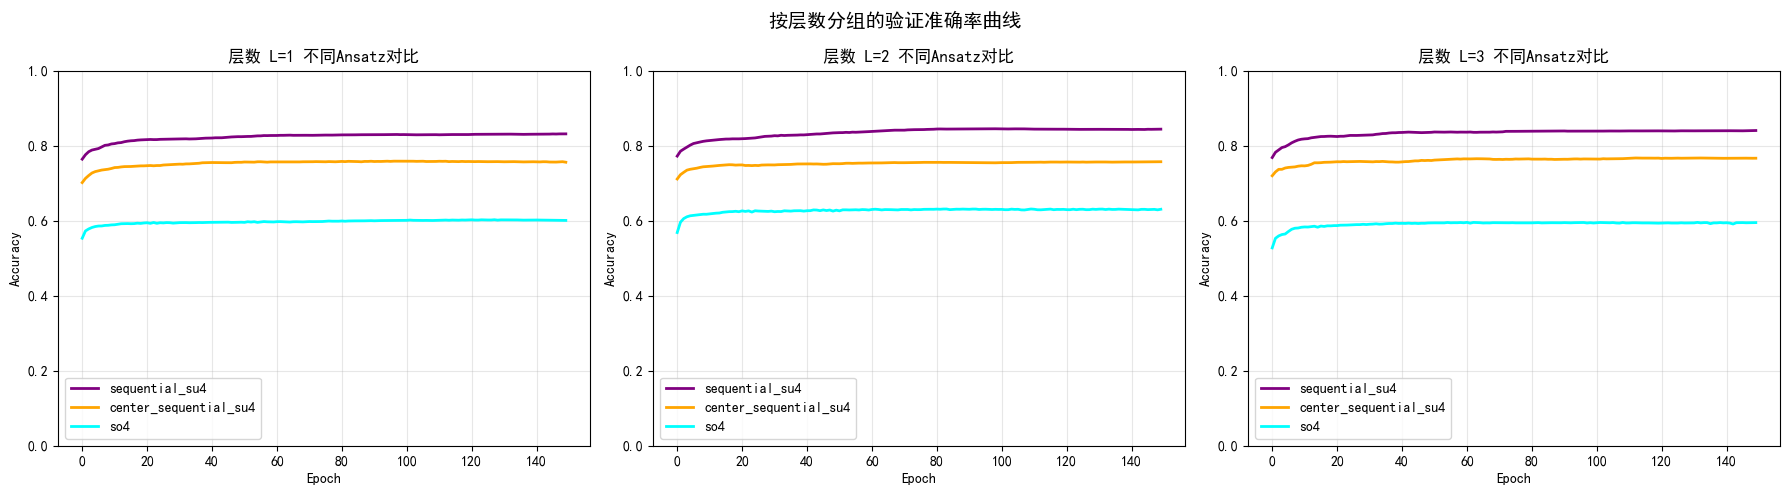

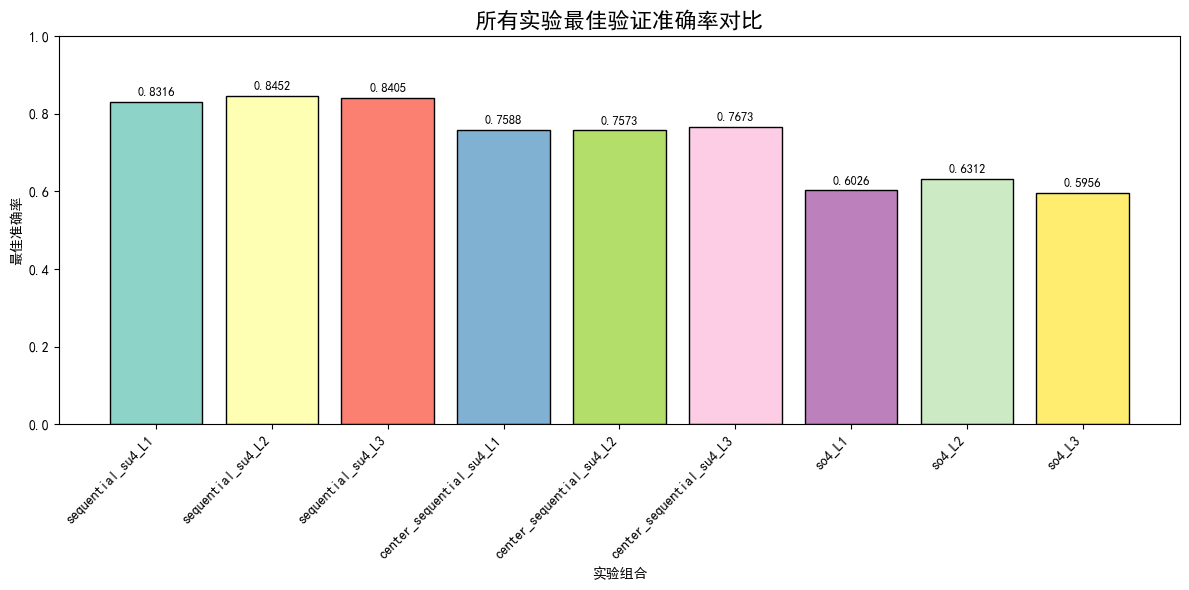

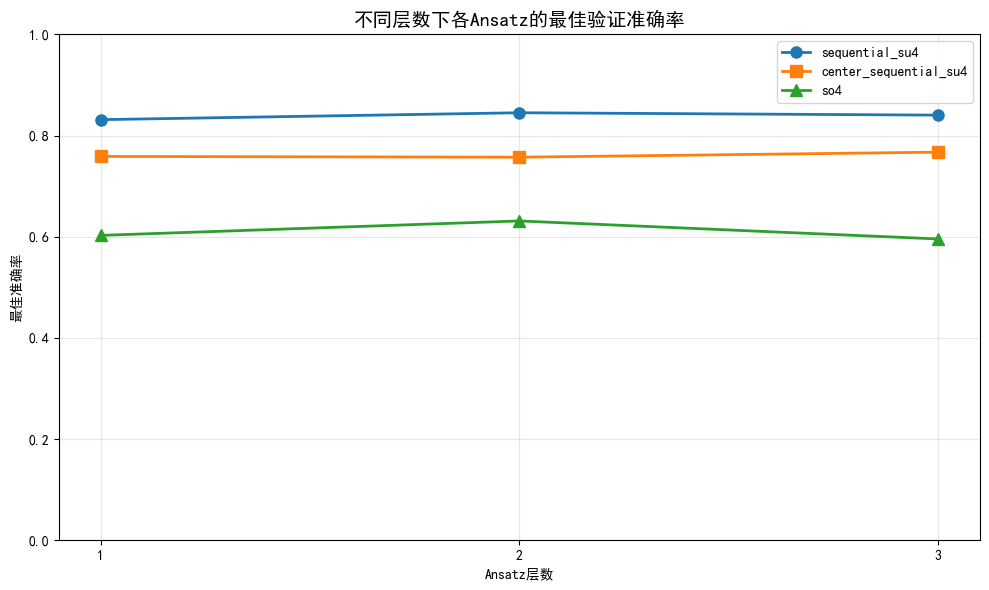


所有实验完成！


In [12]:
# 第六部分：主程序 - 执行9组实验并绘图对比
# ============================================

if __name__ == "__main__":
    # 1. 加载和预处理数据（只做一次）
    print("=" * 60)
    print("步骤1：加载MNIST数据")
    print("=" * 60)
    all_images, all_labels = load_mnist_data()
    print(f"数据大小: {len(all_images)}")
    
    # 2. 划分训练集和测试集
    print("\n" + "=" * 60)
    print("步骤2：划分数据集")
    print("=" * 60)
    train_images, test_images, train_labels, test_labels = train_test_split(
        all_images, all_labels, test_size=TEST_SIZE, random_state=SEED, stratify=all_labels
    )
    print(f"训练集: {len(train_images)} 样本, 测试集: {len(test_images)} 样本")
    
    # 3. 预处理数据
    print("\n" + "=" * 60)
    print("步骤3：PCA降维与归一化")
    print("=" * 60)
    train_dataset, scaler, pca = preprocess_data(train_images, train_labels, is_train=True)
    test_dataset, _, _ = preprocess_data(test_images, test_labels, scaler=scaler, pca=pca, is_train=False)
    
    # 4. 定义实验组合
    ansatz_types = ['sequential_su4', 'center_sequential_su4', 'so4']
    layers_list = LAYERS_LIST  # [1,2,3]
    
    # 存储所有结果
    all_results = {}  # 键: f"{ansatz_type}_L{num_layers}"
    
    print("\n" + "=" * 60)
    print("步骤4：开始9组实验")
    print("=" * 60)
    
    for ansatz_type in ansatz_types:
        for num_layers in layers_list:
            exp_key = f"{ansatz_type}_L{num_layers}"
            print(f"\n{'='*60}")
            print(f"实验 {exp_key} 开始")
            print(f"{'='*60}")
            
            # 训练模型
            train_losses, val_accuracies, best_val_acc = train_model(
                train_dataset=train_dataset,
                val_dataset=test_dataset,
                ansatz_type=ansatz_type,
                num_layers=num_layers,
                num_epochs=NUM_EPOCHS,
                learning_rate=LEARNING_RATE
            )
            
            # 存储结果
            all_results[exp_key] = {
                'train_losses': train_losses,
                'val_accuracies': val_accuracies,
                'best_val_acc': best_val_acc,
                'ansatz_type': ansatz_type,
                'num_layers': num_layers
            }
            
            # 可选：立即绘制单个实验的曲线（此处不重复绘制，后面统一绘制）
    
    # 5. 结果汇总与可视化
    print("\n" + "=" * 60)
    print("步骤5：结果汇总与可视化")
    print("=" * 60)
    
    # 5.1 打印汇总表格
    print("\n所有实验最佳验证准确率汇总：")
    print("-" * 50)
    print(f"{'Ansatz类型':<20} {'层数':<5} {'最佳准确率':<10}")
    print("-" * 50)
    for key, res in all_results.items():
        print(f"{res['ansatz_type']:<20} {res['num_layers']:<5} {res['best_val_acc']:.4f}")
    print("-" * 50)
    
    # 找出最佳组合
    best_key = max(all_results.keys(), key=lambda k: all_results[k]['best_val_acc'])
    best_res = all_results[best_key]
    print(f"\n最佳实验: {best_key}，最佳验证准确率: {best_res['best_val_acc']:.4f}")
    
    # 5.2 绘制每个实验的训练损失曲线（9个子图）
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    fig.suptitle('所有实验的训练损失曲线', fontsize=16)
    
    for i, ansatz_type in enumerate(ansatz_types):
        for j, num_layers in enumerate(layers_list):
            exp_key = f"{ansatz_type}_L{num_layers}"
            ax = axes[i, j]
            losses = all_results[exp_key]['train_losses']
            ax.plot(losses, 'b-', linewidth=1.5)
            ax.set_title(f'{ansatz_type}, L={num_layers}')
            ax.set_xlabel('Epoch')
            ax.set_ylabel('Loss')
            ax.grid(True, alpha=0.3)
            ax.set_ylim(0, max(losses)*1.1 if losses else 2.5)
    
    plt.tight_layout()
    plt.show()
    
    # 5.3 绘制每个实验的验证准确率曲线（9个子图）
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    fig.suptitle('所有实验的验证准确率曲线', fontsize=16)
    
    for i, ansatz_type in enumerate(ansatz_types):
        for j, num_layers in enumerate(layers_list):
            exp_key = f"{ansatz_type}_L{num_layers}"
            ax = axes[i, j]
            accs = all_results[exp_key]['val_accuracies']
            ax.plot(accs, 'r-', linewidth=1.5)
            ax.set_title(f'{ansatz_type}, L={num_layers}')
            ax.set_xlabel('Epoch')
            ax.set_ylabel('Accuracy')
            ax.grid(True, alpha=0.3)
            ax.set_ylim(0, 1.0)
    
    plt.tight_layout()
    plt.show()
    
    # 5.4 按Ansatz类型分组，对比不同层数的验证准确率（3张图）
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    colors = ['blue', 'green', 'red']
    
    for idx, ansatz_type in enumerate(ansatz_types):
        ax = axes[idx]
        for j, num_layers in enumerate(layers_list):
            exp_key = f"{ansatz_type}_L{num_layers}"
            accs = all_results[exp_key]['val_accuracies']
            ax.plot(accs, color=colors[j], linewidth=2, label=f'L={num_layers}')
        ax.set_title(f'{ansatz_type} 不同层数对比')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Accuracy')
        ax.legend()
        ax.grid(True, alpha=0.3)
        ax.set_ylim(0, 1.0)
    
    plt.suptitle('按Ansatz类型分组的验证准确率曲线', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # 5.5 按层数分组，对比不同Ansatz类型的验证准确率（3张图）
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    colors = ['purple', 'orange', 'cyan']
    
    for idx, num_layers in enumerate(layers_list):
        ax = axes[idx]
        for j, ansatz_type in enumerate(ansatz_types):
            exp_key = f"{ansatz_type}_L{num_layers}"
            accs = all_results[exp_key]['val_accuracies']
            ax.plot(accs, color=colors[j], linewidth=2, label=ansatz_type)
        ax.set_title(f'层数 L={num_layers} 不同Ansatz对比')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Accuracy')
        ax.legend()
        ax.grid(True, alpha=0.3)
        ax.set_ylim(0, 1.0)
    
    plt.suptitle('按层数分组的验证准确率曲线', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # 5.6 最佳验证准确率柱状图（9个柱子）
    plt.figure(figsize=(12, 6))
    keys = list(all_results.keys())
    best_accs = [all_results[k]['best_val_acc'] for k in keys]
    colors = plt.cm.Set3(np.linspace(0, 1, len(keys)))
    bars = plt.bar(range(len(keys)), best_accs, color=colors, edgecolor='black')
    
    plt.title('所有实验最佳验证准确率对比', fontsize=16)
    plt.xlabel('实验组合')
    plt.ylabel('最佳准确率')
    plt.xticks(range(len(keys)), keys, rotation=45, ha='right')
    plt.ylim(0, 1.0)
    
    # 在柱子上添加数值
    for bar, acc in zip(bars, best_accs):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{acc:.4f}', ha='center', va='bottom', fontsize=9)
    
    plt.tight_layout()
    plt.show()
    
    # 5.7 不同层数下各Ansatz的最佳准确率折线图
    plt.figure(figsize=(10, 6))
    markers = ['o', 's', '^']
    
    for idx, ansatz_type in enumerate(ansatz_types):
        layer_acc = []
        for num_layers in layers_list:
            exp_key = f"{ansatz_type}_L{num_layers}"
            layer_acc.append(all_results[exp_key]['best_val_acc'])
        plt.plot(layers_list, layer_acc, marker=markers[idx], linewidth=2, markersize=8, label=ansatz_type)
    
    plt.title('不同层数下各Ansatz的最佳验证准确率', fontsize=14)
    plt.xlabel('Ansatz层数')
    plt.ylabel('最佳准确率')
    plt.xticks(layers_list)
    plt.ylim(0, 1.0)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print("\n所有实验完成！")